# CREADIT CARD FRAUD ANALYSIS

### Import Libraries

In [29]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import PowerTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import(
    accuracy_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
    )

### Load Dataset

In [30]:
import pandas as pd

df = pd.read_csv(r"C:\Users\Shravani Kale\Downloads\archive\creditcard.csv")

df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### Explore Dataset

In [31]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [32]:
df.shape

(284807, 31)

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [34]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [35]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

### Target Imbalance Check

In [36]:
print("\nClass Distribution (%):")
print(df["Class"].value_counts(normalize=True)*100)


Class Distribution (%):
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


### Basic Data Clean

In [37]:
print("\nBasic info:")
df.info()

df = df.drop_duplicates()
print("\nShapes after droping duplicates:",df.shape)


Basic info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 2

### Seperate Features And Target

In [38]:
x = df.drop(columns="Class")
y = df["Class"]

### Train Test Split (Before Any Preprocessing)

In [39]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size = 0.20,
    stratify = y,
    random_state = 42
)
print(f"\nTrain Shape: {x_train.shape}, Test Shape:{x_test.shape}")
print(f"\nTrain Fraud Rate: {y_train.mean()*100:.4f}%")
print(f"\nTest Fraud Rate: {y_test.mean()*100:.4f}%")


Train Shape: (226980, 30), Test Shape:(56746, 30)

Train Fraud Rate: 0.1665%

Test Fraud Rate: 0.1674%


### Seperate PCA And NON-PCA Features

In [40]:
pca_features = x_train.iloc[:,1:29]
non_pca_features = x_train[["Time","Amount"]]

### Diagnostic Analysis - PCA Features

In [41]:
diagnosis_pca = {}
for column in pca_features.columns:
    diagnosis_pca[column] = {
        "Missing Values" : pca_features[column].isnull().sum(),
        "Variance" : pca_features[column].var(),
        "Standard Deviation" : pca_features[column].std(),
        "Range" : pca_features[column].max() - pca_features[column].min(),
        "Infinite Values" : pca_features[column].isin([np.inf,-np.inf]).sum()
    }

diagnosis_pca = pd.DataFrame.from_dict(diagnosis_pca,orient="index")
print(f"\nDiagnosis PCA:")
print(diagnosis_pca)


Diagnosis PCA:
     Missing Values  Variance  Standard Deviation      Range  Infinite Values
V1                0  3.791951            1.947293  58.862440                0
V2                0  2.721236            1.649617  94.773457                0
V3                0  2.271863            1.507270  43.063542                0
V4                0  2.007776            1.416960  22.558515                0
V5                0  1.848628            1.359643  66.893795                0
V6                0  1.751389            1.323401  47.553575                0
V7                0  1.440434            1.200181  77.860418                0
V8                0  1.367362            1.169342  93.223927                0
V9                0  1.196956            1.094055  29.029061                0
V10               0  1.151784            1.073212  48.333399                0
V11               0  1.037672            1.018662  16.816387                0
V12               0  0.984790            0.99236

### Diagnostic Analysis - NON-PCA Features (Time & Amount)

In [42]:
diagnosis_non_pca = {}
for column in non_pca_features.columns:
    Q1 = non_pca_features[column].quantile(0.25)
    Q3 = non_pca_features[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 - 1.5 * IQR
    outliers = ((non_pca_features[column] < lower) | (non_pca_features[column] > upper)).sum()

    diagnosis_non_pca[column] = {
        "Missing Values": non_pca_features[column].isnull().sum(),
        "Outliers": outliers,
        "Skewness": non_pca_features[column].skew(),
        "Infinite Values": non_pca_features[column].isin([np.inf,-np.inf]).sum(),
        "Variance": non_pca_features[column].var(),
        "Standard Deviation": non_pca_features[column].std(),
        "Range": non_pca_features[column].max() - non_pca_features[column].min()
    }
diagnosis_non_pca = pd.DataFrame.from_dict(diagnosis_non_pca,orient="index")
print(f"\nDiagnosis Non-PCA")
print(diagnosis_non_pca)


Diagnosis Non-PCA
        Missing Values  Outliers   Skewness  Infinite Values      Variance  \
Time                 0    220146  -0.037474                0  2.255130e+09   
Amount               0    226980  14.393212                0  6.040144e+04   

        Standard Deviation      Range  
Time          47488.214282  172792.00  
Amount          245.767046   19656.53  


### Custom Transformer - IQR Outlier Clipper

In [43]:
class IQRClipper(BaseEstimator, TransformerMixin):
    def fit(self,x,y=None):
        self.q1 = np.percentile(x,25,axis=0)
        self.q3 = np.percentile(x,75,axis=0)
        self.iqr = self.q3 - self.q1
        return self

    def transform(self,x):
        lower = self.q1 - 1.5 * self.iqr
        upper = self.q3 + 1.5 * self.iqr
        return np.clip(x,lower,upper)

### Build Preprocessing Pipeline

In [44]:
non_pca_pipeline = Pipeline(steps=[
    ("Imputer", SimpleImputer(strategy="median")),
    ("Outlier Clipping",IQRClipper()),
    ("Power Transform", PowerTransformer(method="yeo-johnson"))
])
preprocessor = ColumnTransformer(
    transformers = [
        ("non_pca", non_pca_pipeline,["Time","Amount"])
    ],
    remainder = "passthrough"
)

### Full Modeling Pipeline

In [45]:
pipeline = Pipeline(steps=[
    ("preprocessing",preprocessor),
    ("model",LogisticRegression())
])

### Hyperparameter Grid

In [46]:
param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__penalty": ["l2"],
    "model__solver": ["liblinear"],
    "model__class_weight": ["balanced"],
    "model__max_iter": [500]
}

### Stratified Cross-Validation

In [47]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

### Hyperparameter Tuning (optimize Average Precision / PR-AUC)

In [48]:
from sklearn.model_selection import GridSearchCV

# Remove "penalty" from param_grid and use l1_ratio instead.
# For example, use l1_ratio=0 for L2 regularization.
param_grid = {
    "model__C": [0.1, 1, 10],
    "model__class_weight": ["balanced"],
    "model__max_iter": [500, 1000],
    "model__solver": ["liblinear"],
    "model__l1_ratio": [0]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

print("\nStarting GridSearchCV...")
grid_search.fit(x_train, y_train)

print("\n" + "=" * 45)
print("       GRID SEARCH RESULTS")
print("=" * 45)

print("\nBest Parameters:")
for parameter, value in grid_search.best_params_.items():
    print(f"{parameter}: {value}")

print("\nBest Cross-Validation Average Precision (PR-AUC):")
print(f"{grid_search.best_score_:.6f}")

print("\nGrid search completed successfully!")


Starting GridSearchCV...
Fitting 5 folds for each of 6 candidates, totalling 30 fits

       GRID SEARCH RESULTS

Best Parameters:
model__C: 1
model__class_weight: balanced
model__l1_ratio: 0
model__max_iter: 500
model__solver: liblinear

Best Cross-Validation Average Precision (PR-AUC):
0.755663

Grid search completed successfully!


### Prediction on Unseen Test Set

In [49]:
y_pred = grid_search.predict(x_test)
y_prob = grid_search.predict_proba(x_test)[:,1]

### Model Evaluation

In [50]:
print("\n" + "=" *60)
print("MODEL PERFORMANCE ON TEST SET")
print("=" * 60)

print(f"Accuracy          : {accuracy_score(y_test,y_pred):.4f}")
print(f"Balanced Accuracy : {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"Precision         : {precision_score(y_test, y_pred):.4f}")
print(f"Recall            : {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score          : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC           : {roc_auc_score(y_test, y_prob):.4f}")
print(f"PR-AUC            : {average_precision_score(y_test, y_prob):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test,y_pred))
print("\nClassification Matrix:")
print(classification_report(y_test, y_pred, digits=4))


MODEL PERFORMANCE ON TEST SET
Accuracy          : 0.9747
Balanced Accuracy : 0.9243
Precision         : 0.0551
Recall            : 0.8737
F1 Score          : 0.1037
ROC-AUC           : 0.9620
PR-AUC            : 0.6705

Confusion Matrix:
[[55229  1422]
 [   12    83]]

Classification Matrix:
              precision    recall  f1-score   support

           0     0.9998    0.9749    0.9872     56651
           1     0.0551    0.8737    0.1037        95

    accuracy                         0.9747     56746
   macro avg     0.5275    0.9243    0.5455     56746
weighted avg     0.9982    0.9747    0.9857     56746



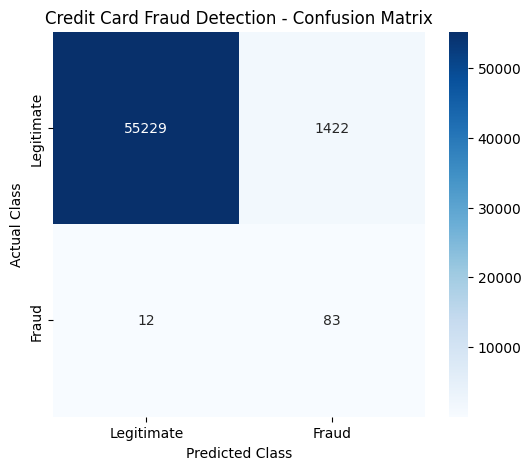

In [53]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Use the best model found by GridSearchCV
y_pred = grid_search.predict(x_test)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("Credit Card Fraud Detection - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

 CREDIT CARD FRAUD DETECTION - MODEL RESULTS


,Metric,Score
0,Accuracy,0.9747
1,Precision,0.0551
2,Recall,0.8737
3,F1-Score,0.1037
4,PR-AUC (Average Precision),0.6705


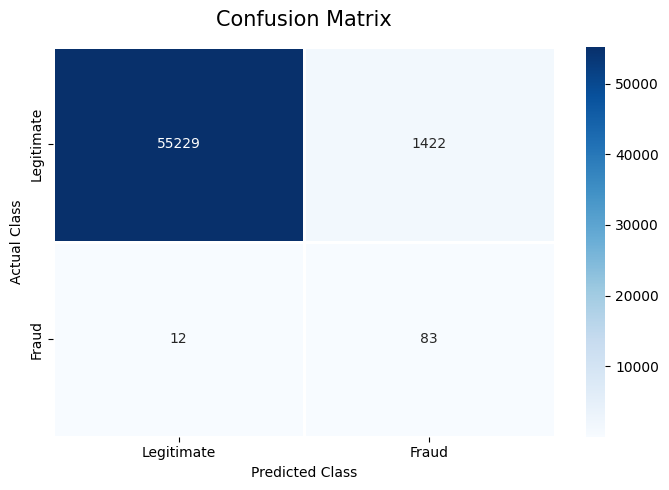

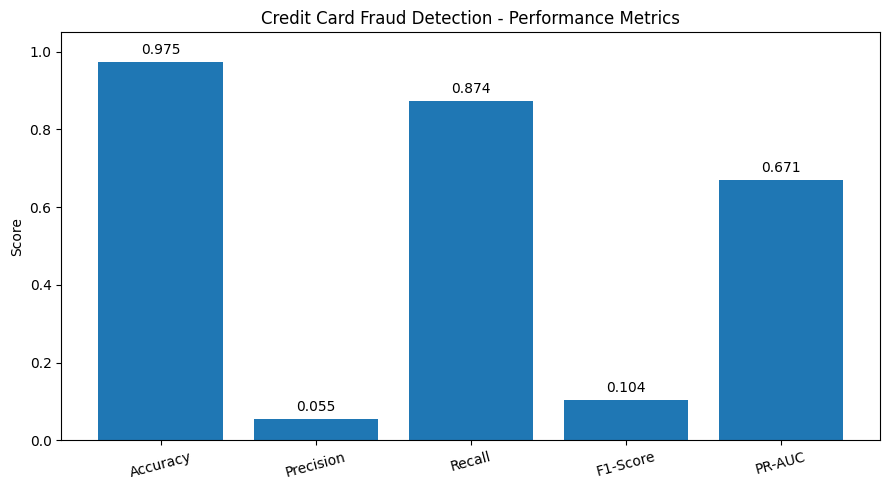

In [54]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, average_precision_score, confusion_matrix,
    classification_report
)
from IPython.display import display

# Use your best trained model
best_model = grid_search.best_estimator_

# Generate predictions
y_pred = best_model.predict(x_test)
y_prob = best_model.predict_proba(x_test)[:, 1]

# Calculate evaluation metrics
results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "PR-AUC (Average Precision)"
    ],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        average_precision_score(y_test, y_prob)
    ]
})

results["Score"] = results["Score"].map(lambda x: f"{x:.4f}")

print("=" * 48)
print(" CREDIT CARD FRAUD DETECTION - MODEL RESULTS")
print("=" * 48)
display(results)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=1,
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)
plt.title("Confusion Matrix", fontsize=15, pad=15)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

# Model performance graph
scores = [
    accuracy_score(y_test, y_pred),
    precision_score(y_test, y_pred, zero_division=0),
    recall_score(y_test, y_pred, zero_division=0),
    f1_score(y_test, y_pred, zero_division=0),
    average_precision_score(y_test, y_prob)
]

labels = ["Accuracy", "Precision", "Recall", "F1-Score", "PR-AUC"]

plt.figure(figsize=(9, 5))
bars = plt.bar(labels, scores)

plt.title("Credit Card Fraud Detection - Performance Metrics")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)

for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{score:.3f}",
        ha="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()